# Lab06 - Metoda transformacji Gabora w rozpoznawaniu obrazów

### 1) wczytywanie emoji

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import NearestNeighbors

os.environ['LOKY_MAX_CPU_COUNT'] = '4'

In [2]:
def load_emojis(folder_name="emojis"):
    script_dir = globals()['_dh'][0]
    script_dir = os.path.join(script_dir, "..")
    folder_path = os.path.join(script_dir, folder_name)
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Nie znaleziono folderu z emoji: {folder_path}")

    emojis = {}
    for filename in sorted(os.listdir(folder_path)):
        if filename.lower().endswith(".png"):
            emoji_name = os.path.splitext(filename)[0]
            emoji_path = os.path.join(folder_path, filename)
            emoji_image = cv2.imread(emoji_path, cv2.IMREAD_UNCHANGED)
            if emoji_image is None:
                raise OSError(f"Nie można wczytać obrazu emoji: {emoji_path}")

            emoji_gray = cv2.cvtColor(emoji_image[:, :, :3], cv2.COLOR_BGR2GRAY)

            alpha = emoji_image[:, :, 3].astype(np.float32) / 255.0
            emoji_gray = emoji_gray.astype(np.float32) / 255.0
            emojis[emoji_name] = (emoji_gray * alpha + (1.0 - alpha))

    if not emojis:
        raise ValueError(f"Folder nie zawiera plików PNG z emoji: {folder_path}")

    return emojis

In [3]:
emojis = load_emojis()
if not emojis:
    raise ValueError("Brak poprawnie załadowanych emojis.")

### 2) budowa filtrów Gabora

In [4]:
# budujemy 12 filtórw Gabora do późniejszej analizy

def build_gabor_filters():
    filters = []
    ksize = 15
    
    # kąty: 0, 45, 90, 135 stopni
    for theta in np.arange(0, np.pi, np.pi / 4): 
        # częstotliwości
        for lamda in [np.pi/4, np.pi/2, np.pi]: 
            sigma = 1.0 
            gamma = 0.5
            
            kern = cv2.getGaborKernel((ksize, ksize), sigma, theta, lamda, gamma, 0, ktype=cv2.CV_32F)
            kern /= 1.5 * kern.sum()  # normalizacja jądra filtru
            filters.append(kern)
            
    return filters

### 3) wydobycie sygnatur energii

In [5]:
def extract_gabor_energy_signatures(img, filters, print = False):
    features = []

    if print: 
        plt.figure(figsize=(8, 4))
    
    for i, kern in enumerate(filters):
        # 1. Splot obrazu z filtrem
        filtered = cv2.filter2D(img, cv2.CV_32F, kern)

        if print:
            plt.subplot(3, 4, i + 1)
            plt.imshow(filtered>0.67, cmap="gray", vmin=0, vmax=1)
            plt.axis("off")
        
        # 2. Sygnatura Energii: średnia z podniesionych do kwadratu wartości odpowiedzi filtru
        energy_mean = np.mean(filtered ** 2)
        
        # 3. Odchylenie standardowe odpowiedzi wzbogaca deskryptor
        energy_std = np.std(filtered ** 2)
        
        features.extend([energy_mean, energy_std])
                                                              
    if print: 
        plt.suptitle(f"Sploty obrazu query z filtrami Gabora (threshold: 0.67)", fontsize=14, y=1.05)
        plt.show()
    
    return np.array(features)


In [6]:
# generujemy deskryptory dla wszystkich emoji

def prepare_all_features(emojis_dict, filters, query_name=None):
    names = list(emojis_dict.keys())
    X_gabor = []
    
    for name in names:
        img = emojis_dict[name]
        gabor_feat = extract_gabor_energy_signatures(img, filters, print=(name == query_name))  # Wyświetlamy tylko dla jednego emoji
        
        # Normalizacja wektora
        norm = np.linalg.norm(gabor_feat)
        if norm > 0:
            gabor_feat = gabor_feat / norm
            
        X_gabor.append(gabor_feat)
        
    return names, np.array(X_gabor)

### 4) wydobycie najpodobniejszego emoji

In [7]:
def retrieve_best_match_gabor(query_name, emojis_dict, filters):
    names, X_gabor = prepare_all_features(emojis_dict, filters, query_name=query_name)
    query_idx = names.index(query_name)
    
    # Baza danych to wszystko oprócz query
    db_names = [n for i, n in enumerate(names) if i != query_idx]
    X_db = np.delete(X_gabor, query_idx, axis=0)
    X_query = X_gabor[query_idx].reshape(1, -1)
    
    # Znajdujemy najbliższego sąsiada w bazie danych
    knn = NearestNeighbors(n_neighbors=1, metric='euclidean')
    knn.fit(X_db)
    distances, indices = knn.kneighbors(X_query)
    
    best_match = db_names[indices[0][0]]
    best_dist = distances[0][0]
    
    return best_match, best_dist


### 5) przedstawienie wyników

In [8]:
def show_results(query_name, emojis, filters, no_print=False):
    if not no_print:
        print(f"Szukany wzorzec: {query_name}")
        print("-" * 50)

    best_name, best_dist = retrieve_best_match_gabor(query_name, emojis, filters)

    if not no_print:
        print(f"Metoda: Sygnatury Energii Gabora | Najlepsze dopasowanie: {best_name} (Dystans: {best_dist:.4f})")

    plt.figure(figsize=(8, 4))
    
    plt.subplot(1, 2, 1)
    plt.imshow(emojis[query_name], cmap="gray", vmin=0, vmax=1)
    plt.title("Query\n(Wzorzec)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(emojis[best_name], cmap="gray", vmin=0, vmax=1)
    plt.title(f"Gabor Energy (1-NN)\n{best_name}\nDist: {best_dist:.2f}")
    plt.axis("off")

    plt.tight_layout()
    plt.suptitle("Image Retrieval - Cechy Energii Gabora", fontsize=14, y=1.1)
    plt.show()


Szukany wzorzec: 1F602
--------------------------------------------------


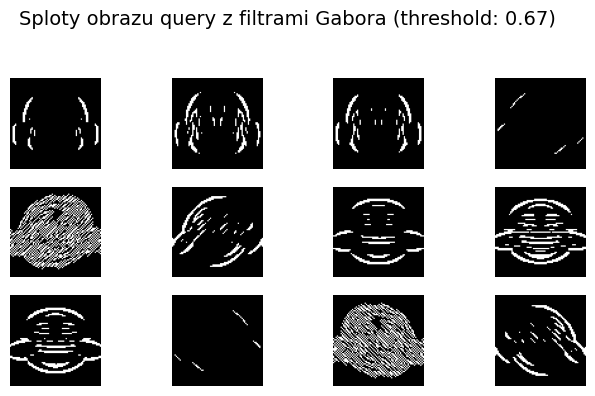

Metoda: Sygnatury Energii Gabora | Najlepsze dopasowanie: 1F92E (Dystans: 0.0081)


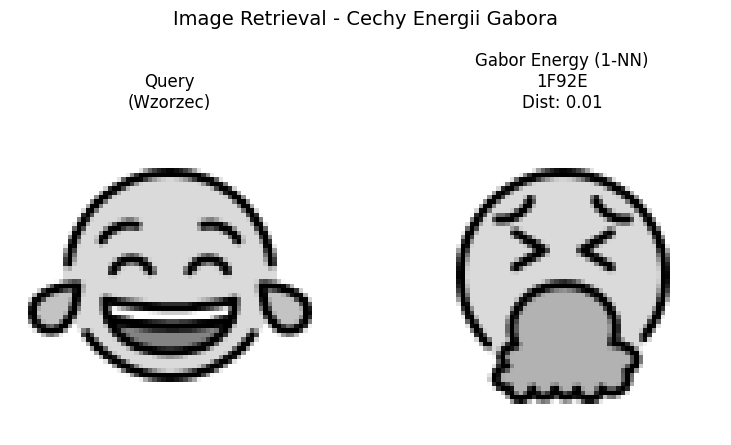

Szukany wzorzec: 1F60D
--------------------------------------------------


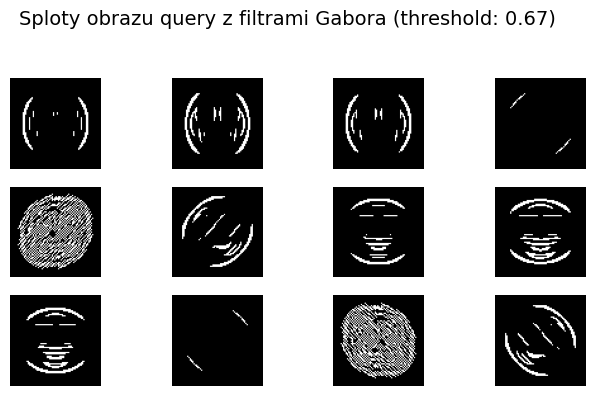

Metoda: Sygnatury Energii Gabora | Najlepsze dopasowanie: 1F62B (Dystans: 0.0105)


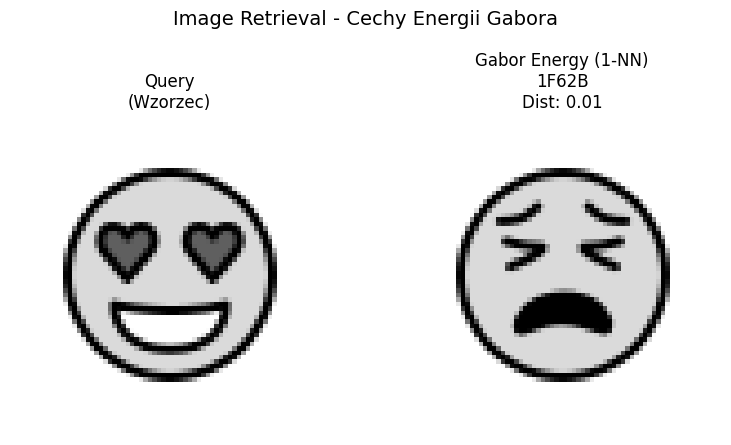

Szukany wzorzec: 1F630
--------------------------------------------------


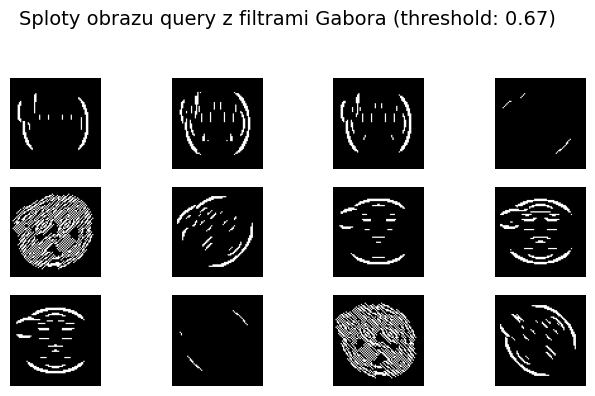

Metoda: Sygnatury Energii Gabora | Najlepsze dopasowanie: 1F618 (Dystans: 0.0055)


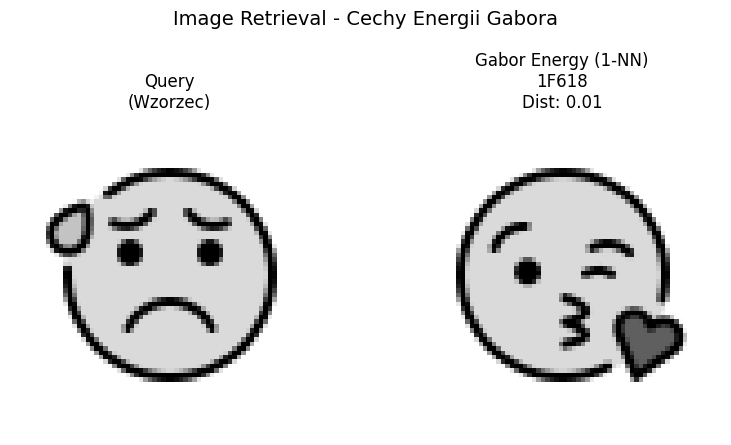

In [9]:
emojis = load_emojis()
gabor_filters = build_gabor_filters()

show_results("1F602", emojis, gabor_filters)
show_results("1F60D", emojis, gabor_filters)
show_results("1F630", emojis, gabor_filters)

**Wnioski:**
 - Wyniki różnią się od większości wyników z poprzednich zadań. Jest to spowodowane tym, że obliczenie średniej i odchylenia niszczy dane o lokalizacji cech. I wtedy np. poziomy łuk uśmiechu myli sie z poziomym łukiem smutku.
 - Zliczamy sumaryczną ilość linii o kącie i częstotliwości. Przez co wynikło podobieństwo emoji w 2 przykładzie (serca i zaciskanie oczy - mają podobną globalną ilość krawędzi skośnych i krzywizn).
 - Mocno kompresujemy obrazy - cała reprezentacja to zaledwie 24 liczby. Takie podejście gubi detale odróżniające wyrazy twarzy.
 - Emoji mają ten sam bazowy kształt i grube czarne kontury przez co dystanse kNN są malutkie (~0.01).
 - Wyniki są podobne do wyników FFT. Dzieje się tak przez to, że oba deskryptory gubią informacje przestrzenne obrazów.